# STATE Kimi R1 — Embedding-norm proximity

This notebook calculates the axis, six prediction/reference metrics, curves and controls directly in its cells. The public bundle contains observed and predicted 2,000-HVG unit means from the model evaluation. Those numeric vectors are the evaluation input, not final score tables. Use Python 3.11, torch 2.7.1, numpy, pandas, scipy, statsmodels, matplotlib, IPython and ipykernel. The four checkpoint tensors below are used only for embedding measurements, without new inference.

## 1. Data source and acquisition

The unit-mean arrays and checkpoints are checksum pinned. ST-HVG-Replogle fewshot final checkpoints correspond to each held-out context.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,zipfile,shutil,ast,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,pearsonr,rankdata,mannwhitneyu
import statsmodels.api as sm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
START=time.time()
CACHE=Path(os.environ.get('STATE_PUBLIC_INPUTS','state_public_inputs')).resolve();CACHE.mkdir(parents=True,exist_ok=True)
RELEASES=Path(os.environ.get('STATE_RELEASE_INPUTS','state_releases')).resolve();RELEASES.mkdir(parents=True,exist_ok=True)
WORK=Path('test-03_outputs').resolve();(WORK/'results').mkdir(parents=True,exist_ok=True)
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def fetch(url,p,size,digest):
    if p.exists() and p.stat().st_size==size and sha(p)==digest:return p
    p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix(p.suffix+'.part')
    with urllib.request.urlopen(urllib.request.Request(url,headers={'User-Agent':'STATE-notebook/1.0'}),timeout=180) as source,tmp.open('wb') as target:
        shutil.copyfileobj(source,target,8388608)
    if tmp.stat().st_size!=size or sha(tmp)!=digest:raise ValueError('Source identity mismatch: '+str(p))
    tmp.replace(p);return p
archive=fetch('https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/state-inputs.zip',CACHE/'state-inputs.zip',440390168,'fb45e9305dcf32bfa9d68ff910f7539707b3e4ff58c695db2e8c5ee8a9e8a9fc')
P=CACHE/'public_bundle/assets/state-kimi-r1'
with zipfile.ZipFile(archive) as z:
    inventory=json.loads(z.read('STATE_INPUTS.json'))
    required=[k for k in inventory if k.startswith('state-kimi-r1/') and (k.endswith('.npz') or k.endswith('.npz.meta.json'))]
    for k in required:
        target=CACHE/'public_bundle/assets'/k;x=inventory[k]
        if target.exists() and target.stat().st_size==x['bytes'] and sha(target)==x['sha256']:continue
        target.parent.mkdir(parents=True,exist_ok=True)
        with z.open('assets/'+k) as source,target.open('wb') as dest:shutil.copyfileobj(source,dest)
        if sha(target)!=x['sha256']:raise ValueError(k)
print('Verified input annotation files:',len(required))

import torch
import statsmodels.formula.api as smf
from scipy.stats import norm

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


Verified input annotation files: 12


In [2]:
WEIGHTS = [{'path': 'fewshot/k562/checkpoints/final.ckpt',
  'bytes': 471695263,
  'sha256': '121ff54db0e6f9f53b2777bbf45139757367ed827a111824213e6bf3777b2618',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/checkpoints/final.ckpt'},
 {'path': 'fewshot/k562/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/pert_onehot_map.pt'},
 {'path': 'fewshot/rpe1/checkpoints/final.ckpt',
  'bytes': 471695263,
  'sha256': '02603032590f51fbcca890e9f201ad07f1c457dbc72580baa97e5aae9b5a3814',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/checkpoints/final.ckpt'},
 {'path': 'fewshot/rpe1/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/pert_onehot_map.pt'},
 {'path': 'fewshot/jurkat/checkpoints/final.ckpt',
  'bytes': 471695263,
  'sha256': '10cfcf01aff649e7f868ed6cf70e763cfbae91d7ba94e2887324a58fbcf5ede5',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/checkpoints/final.ckpt'},
 {'path': 'fewshot/jurkat/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/pert_onehot_map.pt'},
 {'path': 'fewshot/hepg2/checkpoints/final.ckpt',
  'bytes': 471695263,
  'sha256': '9b387a5268f9432b9dd7ad2b1d193b97314835b0d10f50b9b2e7c979cd85b35c',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/checkpoints/final.ckpt'},
 {'path': 'fewshot/hepg2/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/pert_onehot_map.pt'}]
WEIGHT_DIR=CACHE/'kimi1_weights'
for x in WEIGHTS:fetch(x['url'],WEIGHT_DIR/x['path'],x['bytes'],x['sha256'])

## 2. Data processing

Load training/reference means and test means without changing their feature order. Membership in the train and test partitions defines pair exposure. Control means are context-specific.

In [3]:
contexts=['k562','rpe1','jurkat','hepg2']
arrays={}
for ctx in contexts:
    train=np.load(P/f'results/agg_train_{ctx}.npz',allow_pickle=True);test=np.load(P/f'results/unit_means_test_{ctx}.npz',allow_pickle=False)
    assert train['real_means'].shape==train['pred_means'].shape and test['real_mean'].shape==test['pred_mean'].shape
    assert train['real_means'].shape[1]==test['real_mean'].shape[1]==2000
    arrays[ctx]=(train,test)
    print(ctx,'train/reference units:',len(train['counts']),'test units:',len(test['n_cells']))

k562 train/reference units: 4795 test units: 969


rpe1 train/reference units: 4702 test units: 1062


jurkat train/reference units: 4679 test units: 1085


hepg2 train/reference units: 4818 test units: 946


## 3. Axis definition and level construction

A seen pair is present in the training means for its context. E counts the other contexts in which the gene occurs. Levels separate seen pairs from unseen pairs with E=3,2,1. Embedding proximity is the L2 norm of each gene column of `pert_encoder.0.weight`, mapped through that checkpoint’s one-hot dictionary.

In [4]:
manifest_rows=[]
for ctx,(ag,test) in arrays.items():
    keys=list(zip(ag['celltype'].astype(str),ag['pert'].astype(str)));tg=set(test['gene']);allgenes={g for c,g in keys if c==ctx and g!='non-targeting'}|(tg-{'non-targeting'})
    other={c:{g for cell,g in keys if cell==c and g!='non-targeting'} for c in contexts if c!=ctx}
    checkpoint=torch.load(WEIGHT_DIR/f'fewshot/{ctx}/checkpoints/final.ckpt',map_location='cpu',weights_only=False)
    norms=np.linalg.norm(checkpoint['state_dict']['pert_encoder.0.weight'].numpy(),axis=0)
    onehot=torch.load(WEIGHT_DIR/f'fewshot/{ctx}/pert_onehot_map.pt',map_location='cpu',weights_only=False);indices={str(g):int(v.argmax()) for g,v in onehot.items()}
    for g in sorted(allgenes):
        seen=int(g not in tg);E=sum(g in v for v in other.values());manifest_rows.append({'context':ctx,'gene':g,'seen_pair':seen,'exposure_E':E,'level':'seen_pair' if seen else f'unseen_E{E}','emb_norm':norms[indices[g]] if g in indices else np.nan})
manifest=pd.DataFrame(manifest_rows)
display(manifest.groupby(['context','level']).agg(units=('gene','size'),mean_embedding_norm=('emb_norm','mean')))
for ctx,g in manifest.groupby('context'):
    name='proximity_embedding_norms.csv' if ctx=='k562' else f'proximity_embedding_norms_{ctx}.csv';g.to_csv(WORK/'results'/name,index=False)


units  mean_embedding_norm
context level                                
hepg2   seen_pair    395             8.933292
        unseen_E1    131             8.400450
        unseen_E2    340             8.972053
        unseen_E3    474             8.928865
jurkat  seen_pair    453             8.472342
        unseen_E1    179             7.855742
        unseen_E2    422             8.751822
        unseen_E3    483             8.942163
k562    seen_pair    415             9.067822
        unseen_E1    113             8.066159
        unseen_E2    376             9.131652
        unseen_E3    479             9.263966
rpe1    seen_pair    438             9.058586
        unseen_E1    172             8.029696
        unseen_E2    410             8.555314
        unseen_E3    479             8.515248

## 4. Model results and reference scores

Calculate Pearson correlation and mean squared error between observed and predicted changes. Here both STATE predictions and observations subtract the observed control mean. B1 is the within-context mean training perturbation delta. B2 is the mean delta for the same gene in other training contexts, with B1 as fallback.

In [5]:
def calculate_scores(root):
 rows=[];contexts=['k562','rpe1','jurkat','hepg2']
 for ctx in contexts:
  ag=np.load(root/f'results/agg_train_{ctx}.npz',allow_pickle=True)
  keys=list(zip(ag['celltype'].astype(str),ag['pert'].astype(str)))
  rm=dict(zip(keys,ag['real_means']));pm=dict(zip(keys,ag['pred_means']));cnt=dict(zip(keys,ag['counts']))
  means=np.load(root/f'results/unit_means_test_{ctx}.npz',allow_pickle=False)
  tr=dict(zip(means['gene'],means['real_mean']));tp=dict(zip(means['gene'],means['pred_mean']));tn=dict(zip(means['gene'],means['n_cells']))
  allgenes={g for c,g in keys if c==ctx and g!='non-targeting'}|(set(tr)-{'non-targeting'})
  others=[l for l in contexts if l!=ctx]
  exposed={l:{g for c,g in keys if c==l and g!='non-targeting'} for l in others}
  ctrl=rm[(ctx,'non-targeting')]
  delta={(l,g):v-rm[(l,'non-targeting')] for (l,g),v in rm.items() if g!='non-targeting'}
  train=[g for g in allgenes if (ctx,g) in delta]
  baseline1=np.mean([delta[(ctx,g)] for g in train],axis=0)
  for g in sorted(allgenes):
   seen=int(g not in tr);e=sum(g in exposed[l] for l in others)
   if seen:r,p,n=rm[(ctx,g)],pm[(ctx,g)],int(cnt[(ctx,g)])
   else:r,p,n=tr[g],tp[g],int(tn[g])
   yr=r-ctrl;yp=p-ctrl;other=[delta[(l,g)] for l in others if (l,g) in delta];baseline2=np.mean(other,axis=0) if other else baseline1
   d={'context':ctx,'gene':g,'seen_pair':seen,'exposure_E':e,'n_cells':n,'level':('L4_seen_pair' if seen else f'L{e}_unseen_E{e}') if ctx=='k562' else ('seen_pair' if seen else f'unseen_E{e}')}
   for label,v in [('state',yp),('B1',baseline1),('B2',baseline2)]:
    d['pearson_delta_'+label]=float(pearsonr(v,yr).statistic) if np.std(v)>0 and np.std(yr)>0 else np.nan
    d['mse_delta_'+label]=float(np.mean((v-yr)**2))
   d['effect_mag']=float(np.linalg.norm(yr));d['mse_delta_B0']=float(np.mean(yr**2));rows.append(d)
 return pd.DataFrame(rows)

data=calculate_scores(P)
for ctx,g in data.groupby('context'):
    name='per_unit_scores.csv' if ctx=='k562' else f'per_unit_scores_{ctx}.csv';g.to_csv(WORK/'results'/name,index=False)
display(data.groupby(['context','seen_pair'])[['pearson_delta_state','pearson_delta_B1','pearson_delta_B2']].mean())

pearson_delta_state  pearson_delta_B1  pearson_delta_B2
context seen_pair                                                         
hepg2   0                     0.401746          0.411503          0.383013
        1                     0.518794          0.398276          0.378733
jurkat  0                     0.354014          0.316662          0.316812
        1                     0.472401          0.312480          0.307480
k562    0                     0.337242          0.276363          0.317333
        1                     0.446913          0.270126          0.318086
rpe1    0                     0.531401          0.527273          0.368365
        1                     0.649153          0.525743          0.386910

## 5. Curves and controls

Use the same units for STATE and both references. The discovery analysis tests the graded levels and controls for log effect magnitude and log cell count. Confirmation pools the three additional contexts using square-root sample-size weights.

In [6]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import statsmodels.formula.api as smf
LEVEL_ORDER = {'L4_seen_pair': 4, 'L3_unseen_E3': 3, 'L2_unseen_E2': 2, 'L1_unseen_E1': 1}
rng = np.random.default_rng(20260722)

def boot_ci_diff(deep_vals, top_vals, n_boot=10000):
    ds = np.empty(n_boot)
    for b in range(n_boot):
        t = rng.choice(top_vals, size=len(top_vals), replace=True)
        d = rng.choice(deep_vals, size=len(deep_vals), replace=True)
        ds[b] = t.mean() - d.mean()
    return (float(np.percentile(ds, 2.5)), float(np.percentile(ds, 97.5)), float(ds.mean()))

def analyze_discovery():
    df = pd.read_csv(WORK / 'results/per_unit_scores.csv')
    df['level_num'] = df['level'].map(LEVEL_ORDER)
    df = df.sort_values('level_num')
    levels = sorted(df['level'].unique(), key=lambda l: -LEVEL_ORDER[l])
    summ = df.groupby('level').agg(n=('gene', 'size'), pd_state=('pearson_delta_state', 'mean'), pd_state_sd=('pearson_delta_state', 'std'), pd_B1=('pearson_delta_B1', 'mean'), pd_B2=('pearson_delta_B2', 'mean'), mse_state=('mse_delta_state', 'mean'), mse_B1=('mse_delta_B1', 'mean'), mse_B2=('mse_delta_B2', 'mean'), mse_B0=('mse_delta_B0', 'mean'), effect_mag=('effect_mag', 'mean'), n_cells=('n_cells', 'mean')).reindex(levels)
    summ.to_csv(WORK / 'results/spc_table.csv')
    print(summ.round(4))
    rho, p_two = spearmanr(df['level_num'], df['pearson_delta_state'])
    p_one = p_two / 2 if rho > 0 else 1 - p_two / 2
    un = df[df.seen_pair == 0]
    rho_u, p_two_u = spearmanr(un['level_num'], un['pearson_delta_state'])
    p_one_u = p_two_u / 2 if rho_u > 0 else 1 - p_two_u / 2
    top = df[df.level == 'L4_seen_pair']
    deep = df[df.level == 'L1_unseen_E1']
    res = {}
    for col in ['pearson_delta_state', 'pearson_delta_B1', 'pearson_delta_B2']:
        lo, hi, est = boot_ci_diff(deep[col].values, top[col].values)
        res[f'delta_L4_minus_L1_{col}'] = dict(est=est, ci95=[lo, hi])
    df['log_effect'] = np.log(df['effect_mag'])
    df['log_n'] = np.log(df['n_cells'])
    m1 = smf.ols('pearson_delta_state ~ C(level)', data=df).fit()
    m2 = smf.ols('pearson_delta_state ~ C(level) + log_effect + log_n', data=df).fit()
    adj = {k: dict(coef=float(v), p=float(m2.pvalues[k])) for k, v in m2.params.items() if k.startswith('C(level)')}
    summary = dict(n_units=int(len(df)), level_counts={l: int((df.level == l).sum()) for l in levels}, spearman_all=dict(rho=float(rho), p_one_sided=float(p_one)), spearman_unseen_only=dict(rho=float(rho_u), p_one_sided=float(p_one_u)), level_means=summ.round(5).to_dict(), degradation_deltas=res, ancova_adjusted=adj, ancova_R2_unadjusted=float(m1.rsquared), ancova_R2_adjusted=float(m2.rsquared))
    with open(WORK / 'results/analysis_summary.json', 'w') as f:
        json.dump(summary, f, indent=2)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    xs = [LEVEL_ORDER[l] for l in levels]
    for col, lab, mk in [('pearson_delta_state', 'STATE', 'o-'), ('pearson_delta_B1', 'B1 context-mean', 's--'), ('pearson_delta_B2', 'B2 cross-context', '^--')]:
        ax[0].plot(xs, [summ.loc[l, col.replace('pearson_delta_', 'pd_')] for l in levels], mk, label=lab)
    ax[0].set_xticks(xs, [l.replace('_', '\n') for l in levels], fontsize=8)
    ax[0].set_ylabel('pearson_delta')
    ax[0].legend()
    ax[0].set_title('SPC: axis A1 (exposure)')
    for col, lab, mk in [('mse_delta_state', 'STATE', 'o-'), ('mse_delta_B1', 'B1 context-mean', 's--'), ('mse_delta_B2', 'B2 cross-context', '^--')]:
        ax[1].plot(xs, [summ.loc[l, col.replace('mse_delta_', 'mse_')] for l in levels], mk, label=lab)
    ax[1].set_xticks(xs, [l.replace('_', '\n') for l in levels], fontsize=8)
    ax[1].set_ylabel('mse_delta')
    ax[1].legend()
    ax[1].set_title('MSE delta by level')
    fig.tight_layout()
    fig.savefig(WORK / 'results/spc_plot.png', dpi=150)
    print(json.dumps({k: v for k, v in summary.items() if 'means' not in k}, indent=1)[:1500])
analyze_discovery()

                n  pd_state  pd_state_sd   pd_B1   pd_B2  mse_state  mse_B1  \
level                                                                         
L4_seen_pair  415    0.4469       0.3145  0.2701  0.3181     0.0033  0.0052   
L3_unseen_E3  479    0.3147       0.2931  0.2420  0.3149     0.0040  0.0042   
L2_unseen_E2  376    0.3551       0.2981  0.2973  0.3290     0.0049  0.0054   
L1_unseen_E1  113    0.3736       0.2964  0.3527  0.2889     0.0054  0.0062   

              mse_B2  mse_B0  effect_mag   n_cells  
level                                               
L4_seen_pair  0.0085  0.0057      3.0221  129.7325  
L3_unseen_E3  0.0069  0.0046      2.7234  127.0334  
L2_unseen_E2  0.0098  0.0061      3.1613  130.1356  
L1_unseen_E1  0.0147  0.0072      3.4099  126.3717  


{
 "n_units": 1383,
 "level_counts": {
  "L4_seen_pair": 415,
  "L3_unseen_E3": 479,
  "L2_unseen_E2": 376,
  "L1_unseen_E1": 113
 },
 "spearman_all": {
  "rho": 0.10051523285259133,
  "p_one_sided": 9.05073194236073e-05
 },
 "spearman_unseen_only": {
  "rho": -0.08098977191323888,
  "p_one_sided": 0.9941438562280148
 },
 "degradation_deltas": {
  "delta_L4_minus_L1_pearson_delta_state": {
   "est": 0.07352518791469265,
   "ci95": [
    0.010473382910553192,
    0.13486675911565937
   ]
  },
  "delta_L4_minus_L1_pearson_delta_B1": {
   "est": -0.08267464113865633,
   "ci95": [
    -0.12906857310896014,
    -0.03677283958459081
   ]
  },
  "delta_L4_minus_L1_pearson_delta_B2": {
   "est": 0.028844061893777473,
   "ci95": [
    -0.010382244088801793,
    0.06927005115692526
   ]
  }
 },
 "ancova_adjusted": {
  "C(level)[T.L2_unseen_E2]": {
   "coef": 0.015561327103418562,
   "p": 0.36777087507685496
  },
  "C(level)[T.L3_unseen_E3]": {
   "coef": 0.05306667945214145,
   "p": 0.0017806497

In [7]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import norm, spearmanr
import statsmodels.formula.api as smf
CTXS = ['rpe1', 'jurkat', 'hepg2']
rng = np.random.default_rng(20260722)

def boot_ci(x, n=10000, fn=np.mean):
    bs = np.empty(n)
    for b in range(n):
        bs[b] = fn(rng.choice(x, size=len(x), replace=True))
    return (float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)))

def analyze_confirmation():
    per = {}
    for c in CTXS:
        df = pd.read_csv(str(WORK / f'results/per_unit_scores_{c}.csv'))
        nm = pd.read_csv(str(WORK / f'results/proximity_embedding_norms_{c}.csv'))[['gene', 'emb_norm']]
        df = df.merge(nm, on='gene', how='left')
        per[c] = df
    out = {'contexts': {}}
    zs, ws, deltas = ([], [], [])
    for c in CTXS:
        df = per[c]
        s = df[df.seen_pair == 1]
        u = df[df.seen_pair == 0]
        d_state = s.pearson_delta_state.mean() - u.pearson_delta_state.mean()
        d_B1 = s.pearson_delta_B1.mean() - u.pearson_delta_B1.mean()
        d_B2 = s.pearson_delta_B2.mean() - u.pearson_delta_B2.mean()
        v = s.pearson_delta_state.var() / len(s) + u.pearson_delta_state.var() / len(u)
        z = d_state / np.sqrt(v)
        bs = np.empty(5000)
        sv, uv = (s.pearson_delta_state.values, u.pearson_delta_state.values)
        for b in range(5000):
            bs[b] = rng.choice(sv, len(sv), True).mean() - rng.choice(uv, len(uv), True).mean()
        ci = [float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))]
        d = df.copy()
        d['log_effect'] = np.log(d.effect_mag)
        d['log_n'] = np.log(d.n_cells)
        m = smf.ols('pearson_delta_state ~ seen_pair + log_effect + log_n', data=d).fit()
        adj = dict(coef=float(m.params['seen_pair']), p=float(m.pvalues['seen_pair']))
        un = df[df.seen_pair == 0].dropna(subset=['emb_norm'])
        rho, p_two = spearmanr(un.emb_norm, un.pearson_delta_state)
        p_one = p_two / 2 if rho > 0 else 1 - p_two / 2
        un2 = un.copy()
        un2['log_effect'] = np.log(un2.effect_mag)
        un2['log_n'] = np.log(un2.n_cells)
        m2 = smf.ols('pearson_delta_state ~ emb_norm + log_effect + log_n', data=un2).fit()
        a1c_adj = dict(coef=float(m2.params['emb_norm']), p=float(m2.pvalues['emb_norm']))
        out['contexts'][c] = dict(n_seen=int(len(s)), n_unseen=int(len(u)), mean_pd_seen=float(s.pearson_delta_state.mean()), mean_pd_unseen=float(u.pearson_delta_state.mean()), delta_state=float(d_state), delta_boot_ci95=ci, z=float(z), delta_B1=float(d_B1), delta_B2=float(d_B2), adjusted_seen_coef=adj, a1c_spearman_rho=float(rho), a1c_p_one_sided=float(p_one), a1c_adjusted=a1c_adj, a1c_n_unseen=int(len(un)))
        zs.append(z)
        ws.append(np.sqrt(len(s) + len(u)))
        deltas.append(d_state)
    Z = float(np.sum(np.array(zs) * ws) / np.sqrt(np.sum(np.array(ws) ** 2)))
    p_pool = float(1 - norm.cdf(Z))
    pooled_delta = float(np.mean(deltas))
    n_consistent = int(sum((d > 0 for d in deltas)))
    fz, fw = ([], [])
    for c in CTXS:
        r = out['contexts'][c]['a1c_spearman_rho']
        n = out['contexts'][c]['a1c_n_unseen']
        fz.append(np.arctanh(min(max(r, -0.999), 0.999)))
        fw.append(n - 3)
    r_pool = float(np.tanh(np.sum(np.array(fz) * fw) / np.sum(fw)))
    Z_r = float(np.sum(np.array(fz) * np.sqrt(fw)))
    p_r = float(1 - norm.cdf(Z_r))
    out['pooled'] = dict(A1b_stouffer_Z=Z, A1b_p_one_sided=p_pool, A1b_pooled_delta=pooled_delta, A1b_contexts_consistent=n_consistent, A1b_pass=bool(p_pool < 0.04 and pooled_delta >= 0.05 and (n_consistent >= 2)), A1c_pooled_spearman=r_pool, A1c_pooled_Z=Z_r, A1c_p_one_sided=p_r)
    with open(WORK / 'results/confirm_summary.json', 'w') as f:
        json.dump(out, f, indent=2)
    print(json.dumps(out, indent=2))
    rows = []
    for c in CTXS:
        df = per[c]
        for lev in ['seen_pair', 'unseen_E3', 'unseen_E2', 'unseen_E1']:
            sub = df[df.level == lev]
            rows.append(dict(context=c, level=lev, n=len(sub), pd_state=sub.pearson_delta_state.mean(), pd_B1=sub.pearson_delta_B1.mean(), pd_B2=sub.pearson_delta_B2.mean(), mse_state=sub.mse_delta_state.mean(), effect_mag=sub.effect_mag.mean()))
    spc = pd.DataFrame(rows)
    spc.to_csv(WORK / 'results/spc_table_confirm.csv', index=False)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
    order = ['seen_pair', 'unseen_E3', 'unseen_E2', 'unseen_E1']
    for ax, c in zip(axes, CTXS + ['k562']):
        if c == 'k562':
            df = pd.read_csv(WORK / 'results/per_unit_scores.csv')
            df['level'] = df.level.map(lambda l: 'seen_pair' if l == 'L4_seen_pair' else l.replace('L3_', '').replace('L2_', '').replace('L1_', ''))
        else:
            df = per[c]
        for col, lab, mk in [('pearson_delta_state', 'STATE', 'o-'), ('pearson_delta_B1', 'B1', 's--'), ('pearson_delta_B2', 'B2', '^--')]:
            ys = [df.loc[df.level == l, col].mean() for l in order]
            ax.plot(range(4), ys, mk, label=lab, ms=4)
        ax.set_xticks(range(4), ['seen', 'E3', 'E2', 'E1'], fontsize=8)
        ax.set_title(c)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel('pearson_delta')
    axes[-1].legend(loc='lower left', fontsize=8)
    fig.suptitle('SPC: pair-novelty axis (A1b) across contexts — confirmation')
    fig.tight_layout()
    fig.savefig(WORK / 'results/confirm_spc_plot.png', dpi=150)
analyze_confirmation()

{
  "contexts": {
    "rpe1": {
      "n_seen": 438,
      "n_unseen": 1061,
      "mean_pd_seen": 0.6491532363659345,
      "mean_pd_unseen": 0.5314014218276358,
      "delta_state": 0.11775181453829864,
      "delta_boot_ci95": [
        0.08259414939240671,
        0.1526425293722618
      ],
      "z": 6.45107873771258,
      "delta_B1": -0.0015301853994136305,
      "delta_B2": 0.018545641335313556,
      "adjusted_seen_coef": {
        "coef": 0.1197689558919503,
        "p": 5.269564989898557e-33
      },
      "a1c_spearman_rho": 0.4655901329024385,
      "a1c_p_one_sided": 1.706302526903276e-58,
      "a1c_adjusted": {
        "coef": -0.005868433041290207,
        "p": 0.08765427871168702
      },
      "a1c_n_unseen": 1061
    },
    "jurkat": {
      "n_seen": 453,
      "n_unseen": 1084,
      "mean_pd_seen": 0.4724011666805249,
      "mean_pd_unseen": 0.35401361699626743,
      "delta_state": 0.11838754968425746,
      "delta_boot_ci95": [
        0.08759625989534064,
   

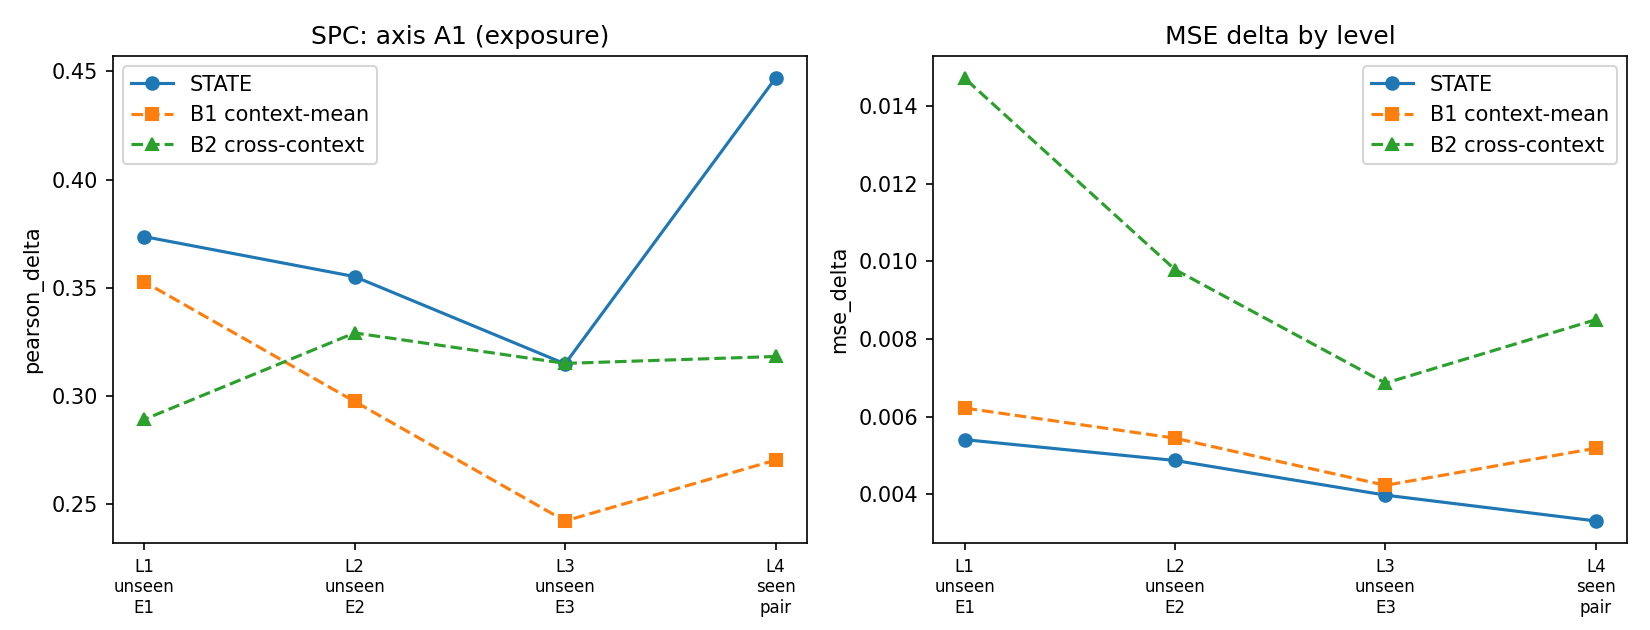

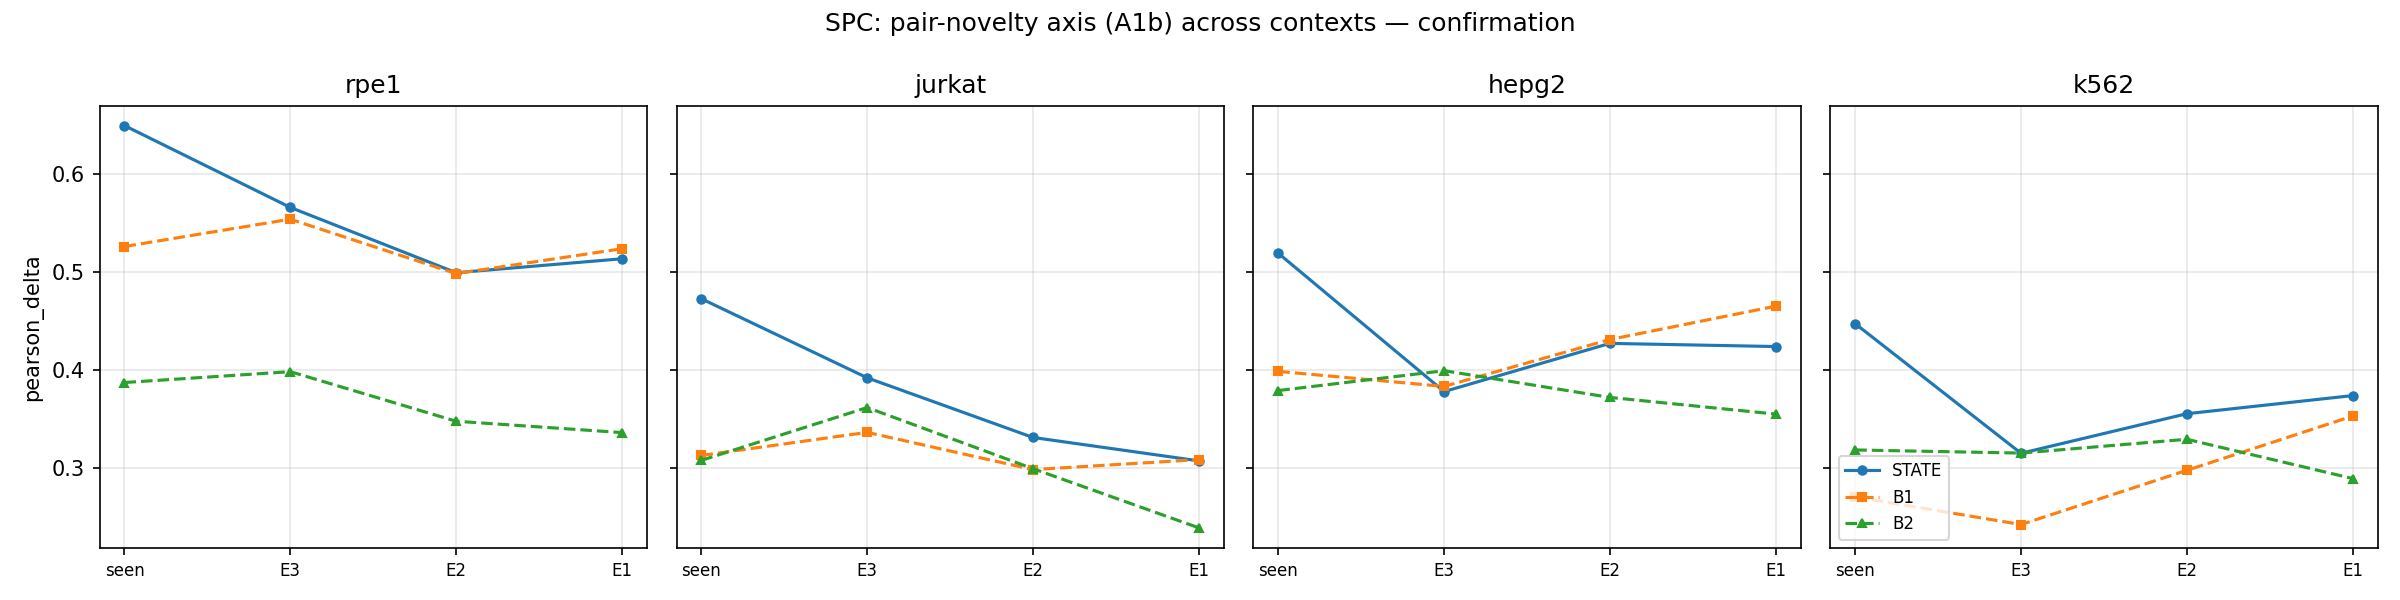

In [8]:
from IPython.display import Image
display(Image(filename=str(WORK/'results/spc_plot.png')))
display(Image(filename=str(WORK/'results/confirm_spc_plot.png')))

,context,ordered_level,n,mean,lo,hi
0,hepg2,1_unseen,131,0.423643,0.364772,0.483915
1,hepg2,2_unseen,340,0.426855,0.391929,0.463889
2,hepg2,3_unseen,474,0.377684,0.348089,0.407658
3,hepg2,4_seen,395,0.518794,0.485706,0.551474
4,jurkat,1_unseen,179,0.306954,0.269084,0.345481
5,jurkat,2_unseen,422,0.330827,0.303105,0.357223
6,jurkat,3_unseen,483,0.391712,0.366455,0.417673
7,jurkat,4_seen,453,0.472401,0.445533,0.497916
8,k562,1_unseen,113,0.373575,0.318906,0.427268
9,k562,2_unseen,376,0.355065,0.325265,0.386418


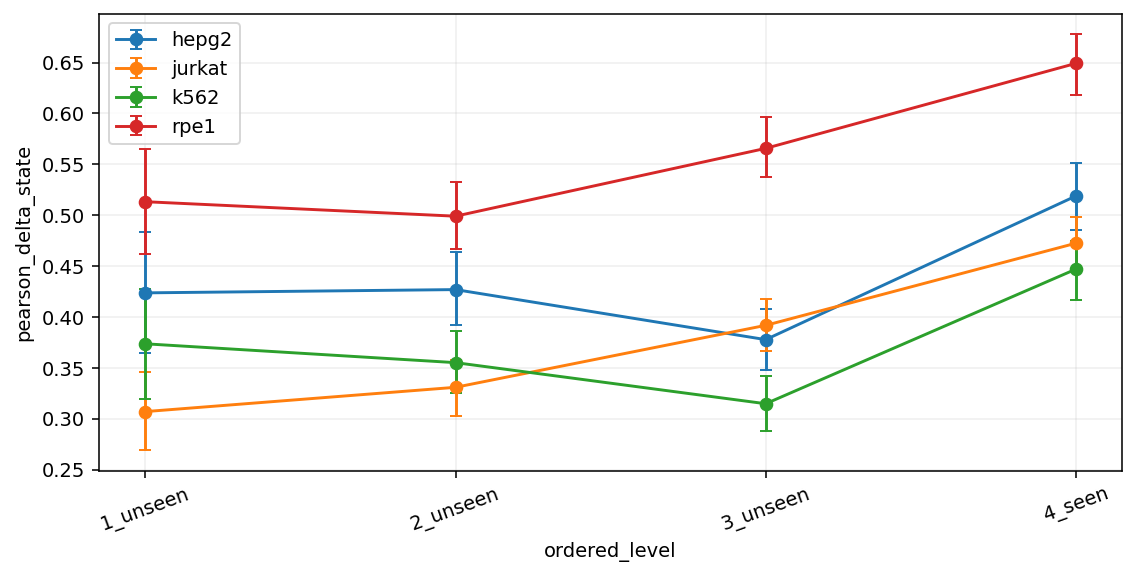

,context,n_seen,n_unseen,mean_pd_seen,mean_pd_unseen,delta_state,delta_boot_ci95,z,delta_B1,delta_B2,adjusted_seen_coef,a1c_spearman_rho,a1c_p_one_sided,a1c_adjusted,a1c_n_unseen
0,rpe1,438,1061,0.649153,0.531401,0.117752,"[0.08259414939240671, 0.1526425293722618]",6.451079,-0.001530,0.018546,"{'coef': 0.1197689558919503, 'p': 5.2695649898...",0.465590,1.706303e-58,"{'coef': -0.005868433041290207, 'p': 0.0876542...",1061
1,jurkat,453,1084,0.472401,0.354014,0.118388,"[0.08759625989534064, 0.14928452258315766]",7.492029,-0.004181,-0.009332,"{'coef': 0.13284214885298906, 'p': 2.211096971...",0.545164,3.025316e-85,"{'coef': 0.017352272071075356, 'p': 5.06869295...",1084
2,hepg2,395,945,0.518794,0.401746,0.117048,"[0.07845545711425012, 0.15669077739454448]",5.860952,-0.013227,-0.004280,"{'coef': 0.10907551412880193, 'p': 1.076408226...",0.499152,5.452144e-61,"{'coef': 0.00735895202535103, 'p': 0.033263204...",945


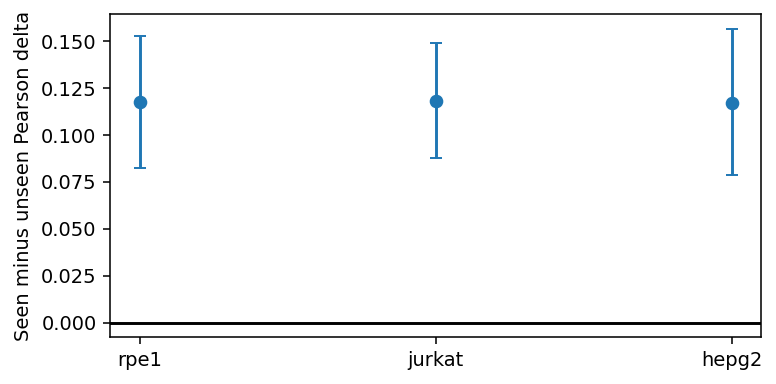

In [9]:
def draw(data,x,y,group):
    rng=np.random.default_rng(7);rows=[]
    for keys,g in data.groupby([group,x],observed=True,sort=True):
        values=g[y].dropna().to_numpy();boot=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(2000)])
        rows.append({group:keys[0],x:keys[1],'n':len(values),'mean':values.mean(),'lo':np.quantile(boot,.025),'hi':np.quantile(boot,.975)})
    tab=pd.DataFrame(rows);display(tab)
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for label,g in tab.groupby(group,sort=False):
        ix=np.arange(len(g));ax.errorbar(ix,g['mean'],yerr=np.maximum(0,np.vstack([g['mean']-g.lo,g.hi-g['mean']])),marker='o',capsize=3,label=str(label));ax.set_xticks(ix,g[x].astype(str),rotation=20)
    ax.set(xlabel=x,ylabel=y);ax.legend();ax.grid(alpha=.2);display_figure(fig);plt.close(fig)
    return tab

def partial_spearman(frame,x,y,controls):
    d=frame[[x,y,*controls]].dropna();a=rankdata(d[x]);b=rankdata(d[y]);C=np.column_stack([np.ones(len(d)),*[rankdata(d[c]) for c in controls]])
    a=a-C@np.linalg.lstsq(C,a,rcond=None)[0];b=b-C@np.linalg.lstsq(C,b,rcond=None)[0]
    return pearsonr(a,b)

plot_data=data.copy();plot_data['ordered_level']=plot_data.apply(lambda r:'4_seen' if r.seen_pair else str(r.exposure_E)+'_unseen',axis=1)
curve=draw(plot_data,'ordered_level','pearson_delta_state','context')
confirmation=json.loads((WORK/'results/confirm_summary.json').read_text());discovery=json.loads((WORK/'results/analysis_summary.json').read_text())
contrasts=pd.DataFrame([{'context':k,**v} for k,v in confirmation['contexts'].items()]);display(contrasts)
fig,ax=plt.subplots(figsize=(6,3));lower=np.array([v[0] for v in contrasts.delta_boot_ci95]);upper=np.array([v[1] for v in contrasts.delta_boot_ci95]);ax.errorbar(contrasts.context,contrasts.delta_state,yerr=np.maximum(0,np.vstack([contrasts.delta_state-lower,upper-contrasts.delta_state])),fmt='o',capsize=3);ax.axhline(0,color='black');ax.set(ylabel='Seen minus unseen Pearson delta');display_figure(fig);plt.close(fig)

,panel,norm_quartile,n,mean,lo,hi
0,hepg2,"(4.5649999999999995, 7.405]",237,0.186638,0.156104,0.218023
1,hepg2,"(7.405, 8.671]",236,0.325190,0.285785,0.366411
2,hepg2,"(8.671, 10.193]",236,0.479575,0.439518,0.517769
3,hepg2,"(10.193, 14.564]",236,0.616494,0.579671,0.651865


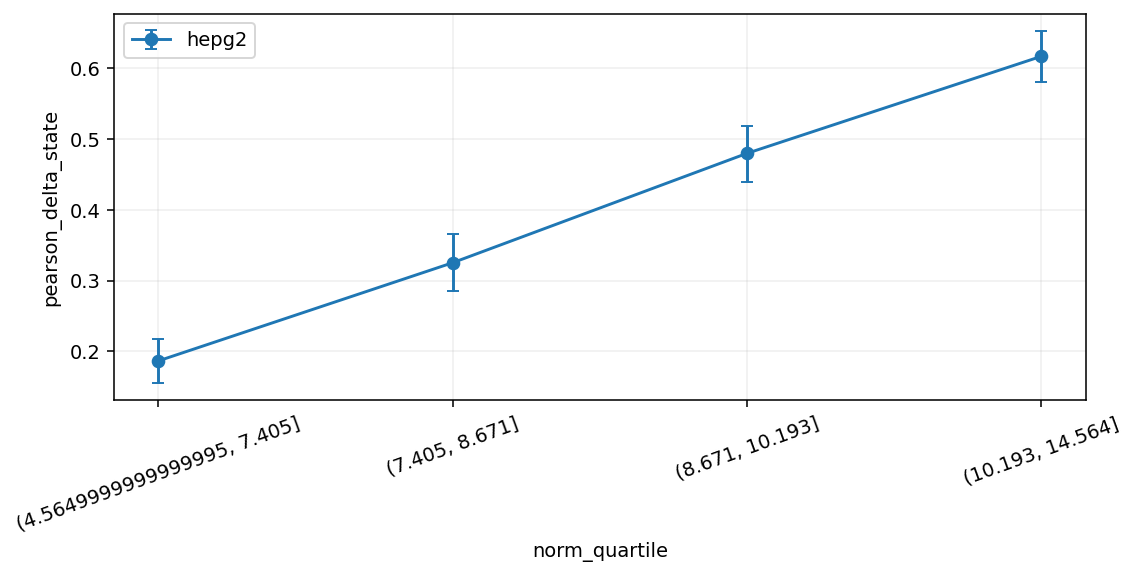

,panel,norm_quartile,n,mean,lo,hi
0,jurkat,"(4.239999999999999, 7.234]",271,0.145503,0.124855,0.166874
1,jurkat,"(7.234, 8.581]",271,0.276922,0.246566,0.304670
2,jurkat,"(8.581, 9.984]",271,0.447396,0.413522,0.480738
3,jurkat,"(9.984, 14.561]",271,0.546234,0.515011,0.576338


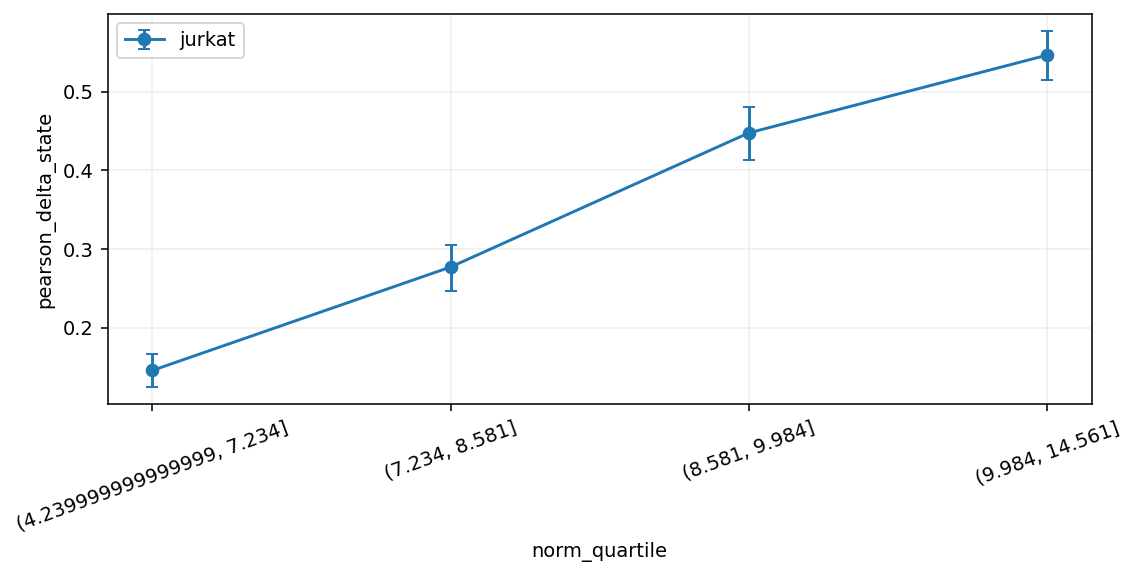

,panel,norm_quartile,n,mean,lo,hi
0,k562,"(4.662999999999999, 7.64]",242,0.129745,0.107653,0.153022
1,k562,"(7.64, 8.887]",242,0.235965,0.205933,0.268384
2,k562,"(8.887, 10.342]",242,0.407110,0.373808,0.442626
3,k562,"(10.342, 14.732]",242,0.576147,0.544803,0.607270


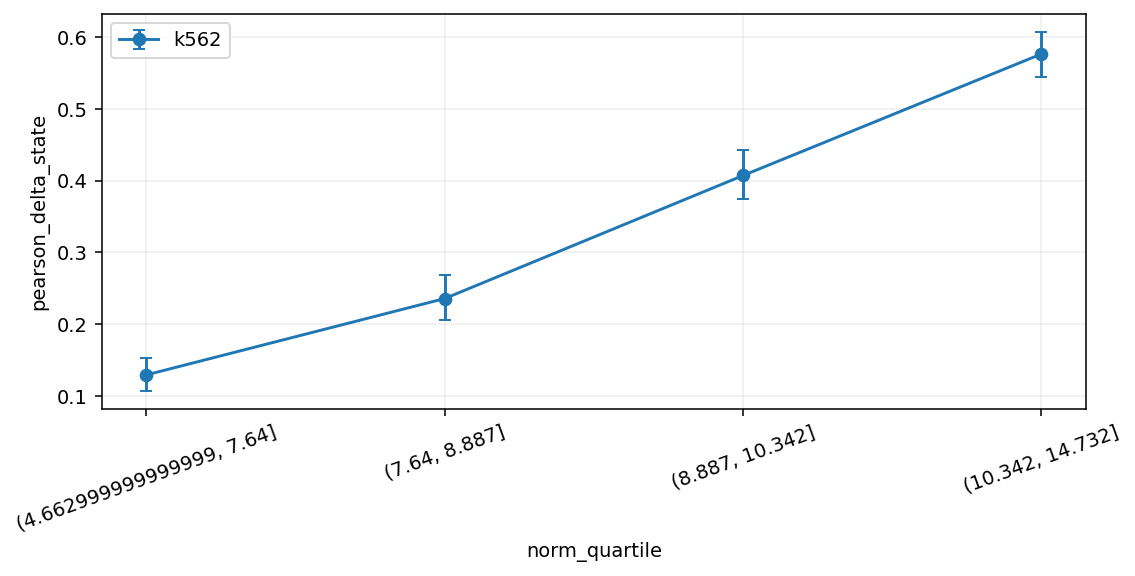

,panel,norm_quartile,n,mean,lo,hi
0,rpe1,"(4.859, 6.936]",266,0.366188,0.326935,0.405187
1,rpe1,"(6.936, 8.113]",265,0.413153,0.373978,0.453805
2,rpe1,"(8.113, 9.8]",265,0.605355,0.565710,0.641974
3,rpe1,"(9.8, 15.277]",265,0.741534,0.712503,0.769631


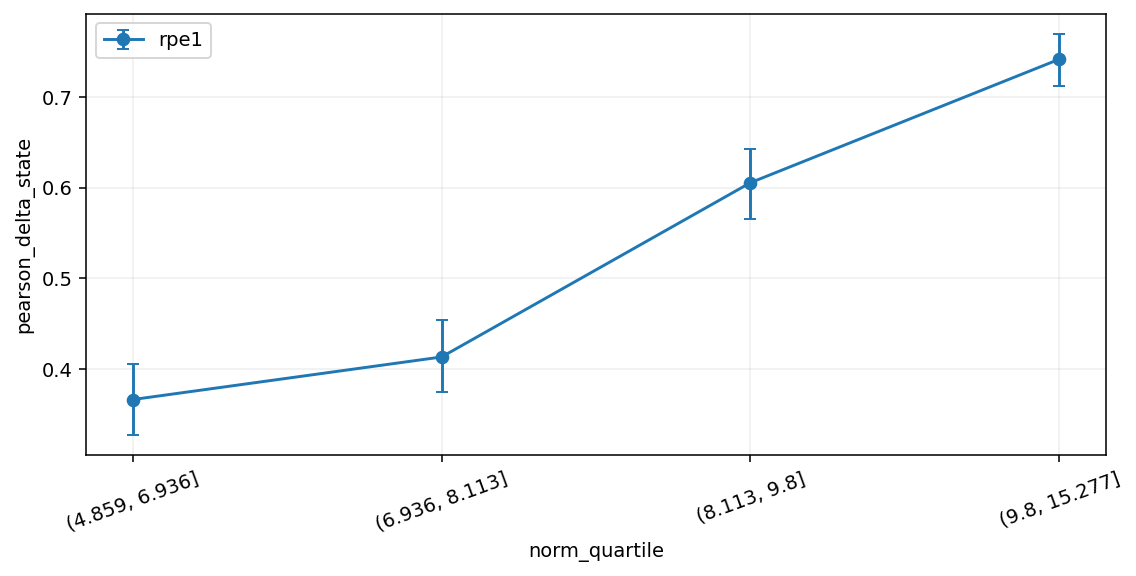

In [10]:
norm_data=data.merge(manifest[['context','gene','emb_norm']],on=['context','gene'],validate='one_to_one')
for ctx,g in norm_data[norm_data.seen_pair.eq(0)].groupby('context'):
    q=g.copy();q['norm_quartile']=pd.qcut(q.emb_norm,4,duplicates='drop');q['panel']=ctx;draw(q,'norm_quartile','pearson_delta_state','panel')

## 6. What the agent decided, and why

In [11]:
p=confirmation['pooled'];print('Pooled within-unseen embedding correlation:',p['A1c_pooled_spearman']);print('Per-context adjusted embedding coefficients:',{k:v['a1c_adjusted'] for k,v in confirmation['contexts'].items()});print('Decision: embedding proximity is a secondary diagnostic; require directional within-unseen and adjusted evidence across contexts, not merely a pooled raw association.')

Pooled within-unseen embedding correlation: 0.504527501576208
Per-context adjusted embedding coefficients: {'rpe1': {'coef': -0.005868433041290207, 'p': 0.08765427871168702}, 'jurkat': {'coef': 0.017352272071075356, 'p': 5.068692953343728e-08}, 'hepg2': {'coef': 0.00735895202535103, 'p': 0.0332632042282173}}
Decision: embedding proximity is a secondary diagnostic; require directional within-unseen and adjusted evidence across contexts, not merely a pooled raw association.


In [12]:
(WORK/'execution_record.json').write_text(json.dumps({'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'unit_mean_input':True,'score_rows':len(data),'checkpoints':WEIGHTS,'model_inference_performed':False,'external_custom_code_used':False},indent=2))

2853